In [5]:
# ============================================================================
# COMPREHENSIVE AGN VARIABILITY PIPELINE: Petrecca Dual-Timescale Method
# ============================================================================

import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patheffects as patheffects
from scipy.interpolate import interp1d
from astropy.timeseries import LombScargle
import warnings

warnings.filterwarnings('ignore')

# ----------------------------------------------------------------------------
# 1. GLOBAL CONFIGURATIONS
# ----------------------------------------------------------------------------
base_dir = r"ztffp_final_data_2025" 
csv_meta_path = r"wu_shen_selected_columns.csv"
BANDS_TO_PROCESS = ['g', 'r']

# Petrecca Method Parameters
MIN_CADENCE_DAYS = 1.0 
SEASON_GAP_DAYS = 100.0    # Minimum gap to define a new observing season
f_max_nyquist = 1.0 / (2.0 * MIN_CADENCE_DAYS) 

# Physical Filters and Grid Edges
Z_MIN, Z_MAX = 0.4, 0.5
mass_edges = [7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
edd_edges  = [-2.5, -2.0, -1.5, -1.0, -0.5, 0.0, 0.5] 

N_BINS_FREQ = 40 # Number of logarithmic bins for the PSD
MIN_OBJS_PER_BIN = 3 # Minimum objects required to plot a stacked line

# Colormap for dynamic plotting
cmap = plt.get_cmap('tab10')

# ----------------------------------------------------------------------------
# MAIN LOOP OVER BANDS
# ----------------------------------------------------------------------------
for band in BANDS_TO_PROCESS:
    print(f"\n{'='*60}")
    print(f" STARTING PROCESSING FOR BAND: '{band.upper()}'")
    print(f"{'='*60}")
    
    plots_dir = f"plots_Petrecca_Advanced_band_{band}"
    os.makedirs(plots_dir, exist_ok=True)

    # ------------------------------------------------------------------------
    # 2. DATA LOADING & DUAL-TIMESCALE PROCESSING
    # ------------------------------------------------------------------------
    print("Loading metadata and applying Z, Mass, and Eddington filters...")
    try:
        meta = pd.read_csv(csv_meta_path.replace("\\", "/"))
        ra_cat, dec_cat = meta['RA'].values, meta['DEC'].values
        logmbh_cat, logedd_cat = meta['LOGMBH'].values, meta['LOGLEDD_RATIO'].values
        z_col = 'Z_DR16Q' if 'Z_DR16Q' in meta.columns else 'Z'
        z_cat = meta[z_col].values
    except FileNotFoundError:
        print(f"WARNING: Metadata catalog {csv_meta_path} not found.")
        continue

    folders = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f)) and "plots" not in f]
    valid_data = []

    for folder in tqdm(folders, desc=f"Extracting Seasons & PSD (Band {band})"):
        try: ra_f, dec_f = map(float, folder.split('_'))
        except: continue
        
        # Crossmatch
        dist = np.sqrt((ra_cat - ra_f)**2 + (dec_cat - dec_f)**2)
        idx = np.argmin(dist)
        if dist[idx] > 1e-4: continue
        
        m, e, z = logmbh_cat[idx], logedd_cat[idx], z_cat[idx]
        
        # Apply physical and redshift filters
        if np.isnan(m) or np.isnan(e) or np.isnan(z): continue
        if z < Z_MIN or z > Z_MAX: continue
        if m < mass_edges[0] or m >= mass_edges[-1]: continue
        if e < edd_edges[0] or e >= edd_edges[-1]: continue

        txt_files = glob.glob(os.path.join(base_dir, folder, f"*_ztf_{band}_filtered.txt"))
        if not txt_files: continue
        
        try:
            df = pd.read_csv(txt_files[0])
            if len(df) < 10 or 'mjd' not in df.columns or 'flux' not in df.columns: continue
                
            df = df.sort_values('mjd')
            t_all = df['mjd'].values
            f_all = df['flux'].values
            
            # Global normalization
            y_norm_all = (f_all - np.median(f_all)) / np.median(f_all)
            
            # --- Petrecca Logic: Separate Seasons ---
            gaps = np.diff(t_all)
            season_breaks = np.where(gaps > SEASON_GAP_DAYS)[0] + 1
            season_indices = np.split(np.arange(len(t_all)), season_breaks)
            
            seasons_t, seasons_f_norm = [], []
            t_season_means, f_season_means = [], []
            
            for s_idx in season_indices:
                if len(s_idx) > 3: # Require minimum points per season
                    t_s, f_s = t_all[s_idx], f_all[s_idx]
                    seasons_t.append(t_s)
                    seasons_f_norm.append((f_s - np.median(f_all)) / np.median(f_all))
                    t_season_means.append(np.mean(t_s))
                    f_season_means.append(np.mean(f_s))
            
            if len(t_season_means) < 2: continue
            
            y_season_norm = (np.array(f_season_means) - np.median(f_all)) / np.median(f_all)
            
            valid_data.append({
                't_raw': t_all, 'flux_norm': y_norm_all, 
                'seasons_t': seasons_t, 'seasons_f_norm': seasons_f_norm,
                't_season_means': np.array(t_season_means), 'flux_season_means': y_season_norm,
                'T_total': t_all.max() - t_all.min(), 
                'LOGMBH': m, 'LOGLEDD_RATIO': e, 'Z': z
            })
                
        except Exception as error: 
            continue

    if not valid_data:
        print(f"No valid data for band {band} after filters. Skipping...")
        continue

    print(f"Total valid objects for band {band}: {len(valid_data)}")

    # ------------------------------------------------------------------------
    # 3. GLOBAL FREQUENCY GRID & PSD CALCULATION
    # ------------------------------------------------------------------------
    global_fmin = 1.0 / max([d['T_total'] for d in valid_data])
    bin_edges = np.logspace(np.log10(global_fmin), np.log10(f_max_nyquist), N_BINS_FREQ + 1)
    bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])

    binned_matrix_fft = np.full((len(valid_data), N_BINS_FREQ), np.nan)
    binned_matrix_ls = np.full((len(valid_data), N_BINS_FREQ), np.nan)

    for i, d in enumerate(valid_data):
        # Lomb-Scargle (Full light curve for comparison)
        ls = LombScargle(d['t_raw'] - d['t_raw'].min(), d['flux_norm'])
        f_ls, p_ls = ls.autopower(normalization='psd', maximum_frequency=f_max_nyquist)
        
        # Dual-Timescale FFT (Petrecca approximation)
        f_combined, p_combined = [], []
        
        # Low Frequencies (Inter-season means)
        t_low = d['t_season_means']
        f_low_norm = d['flux_season_means']
        t_grid_low = np.linspace(t_low.min(), t_low.max(), int((t_low.max()-t_low.min())/MIN_CADENCE_DAYS)+1)
        if len(t_grid_low) > 1:
            intp_low = interp1d(t_low, f_low_norm, kind='linear')(t_grid_low)
            fft_low = np.fft.rfft(intp_low)
            freqs_l = np.fft.rfftfreq(len(t_grid_low), d=MIN_CADENCE_DAYS)[1:]
            powers_l = ((np.abs(fft_low)**2) * (2.0 * MIN_CADENCE_DAYS / len(t_grid_low)))[1:]
            # Filter to keep only frequencies below the season gap threshold
            mask_low = freqs_l < (1.0 / SEASON_GAP_DAYS)
            f_combined.extend(freqs_l[mask_low])
            p_combined.extend(powers_l[mask_low])
            
        # High Frequencies (Intra-season)
        for t_s, f_s in zip(d['seasons_t'], d['seasons_f_norm']):
            t_grid_high = np.linspace(t_s.min(), t_s.max(), int((t_s.max()-t_s.min())/MIN_CADENCE_DAYS)+1)
            if len(t_grid_high) > 1:
                intp_high = interp1d(t_s, f_s, kind='linear')(t_grid_high)
                fft_high = np.fft.rfft(intp_high)
                freqs_h = np.fft.rfftfreq(len(t_grid_high), d=MIN_CADENCE_DAYS)[1:]
                powers_h = ((np.abs(fft_high)**2) * (2.0 * MIN_CADENCE_DAYS / len(t_grid_high)))[1:]
                f_combined.extend(freqs_h)
                p_combined.extend(powers_h)
                
        f_combined, p_combined = np.array(f_combined), np.array(p_combined)
        
        # Binning to standard grid
        for f_arr, p_arr, out_matrix in zip([f_ls, f_combined], [p_ls, p_combined], [binned_matrix_ls, binned_matrix_fft]):
            if len(f_arr) == 0: continue
            inds = np.searchsorted(bin_edges, f_arr, side='right') - 1
            valid_mask = (inds >= 0) & (inds < N_BINS_FREQ)
            if np.any(valid_mask):
                bid, pw = inds[valid_mask], p_arr[valid_mask]
                sums = np.bincount(bid, weights=pw, minlength=N_BINS_FREQ)
                counts = np.bincount(bid, minlength=N_BINS_FREQ)
                mask = counts > 0
                out_matrix[i, mask] = sums[mask] / counts[mask]

    # ------------------------------------------------------------------------
    # 4. PLOT: LC INTERPOLATION VISUALIZATION (Plot 1)
    # ------------------------------------------------------------------------
    print(f"Generating LC Interpolation Plot (Band {band})...")
    ex_data = valid_data[0] 
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    ax1.scatter(ex_data['t_raw'], ex_data['flux_norm'], color='gray', s=20, alpha=0.7, label='Observations (ZTF)')
    ax1.scatter(ex_data['t_season_means'], ex_data['flux_season_means'], color='crimson', s=80, marker='D', edgecolor='black', zorder=5, label='Seasonal Means')
    ax1.set_ylabel('Normalized Flux', fontweight='bold')
    ax1.set_title(f'Petrecca Separation Method (Band {band.upper()}, z={ex_data["Z"]:.2f})', fontweight='bold')
    ax1.legend()
    ax1.grid(ls=':', alpha=0.5)

    if len(ex_data['t_season_means']) > 1:
        t_grid_low = np.linspace(ex_data['t_season_means'].min(), ex_data['t_season_means'].max(), 200)
        intp_low = interp1d(ex_data['t_season_means'], ex_data['flux_season_means'], kind='linear', bounds_error=False, fill_value='extrapolate')(t_grid_low)
        ax2.plot(t_grid_low, intp_low, color='crimson', lw=1.5, ls='--', alpha=0.4, label='Low Freq. Trend')
        ax2.scatter(ex_data['t_season_means'], ex_data['flux_season_means'], color='crimson', s=60, marker='D', edgecolor='black', zorder=5, label='Low Freq. Nodes')

    for s_idx, (t_s, f_s) in enumerate(zip(ex_data['seasons_t'], ex_data['seasons_f_norm'])):
        t_grid_high = np.linspace(t_s.min(), t_s.max(), int((t_s.max()-t_s.min())/MIN_CADENCE_DAYS) + 1)
        if len(t_grid_high) > 1:
            intp_high = interp1d(t_s, f_s, kind='linear')(t_grid_high)
            lbl = 'High Freq. Points (Intra-season)' if s_idx == 0 else ""
            ax2.scatter(t_grid_high, intp_high, color='dodgerblue', s=12, alpha=0.8, zorder=3, label=lbl)

    ax2.set_xlabel('Time [MJD]', fontweight='bold')
    ax2.set_ylabel('Interpolated Signal', fontweight='bold')
    ax2.legend()
    ax2.grid(ls=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, f"LC_Interpolation_Petrecca_band_{band}.png"), dpi=200)
    plt.close()

    # ------------------------------------------------------------------------
    # 5. DYNAMIC PLOTTING FUNCTION FOR GRIDS AND STACKED PSDs
    # ------------------------------------------------------------------------
    LOGMBH_arr = np.array([d['LOGMBH'] for d in valid_data])
    LOGLEDD_arr = np.array([d['LOGLEDD_RATIO'] for d in valid_data])
    
    def plot_grid_and_psd(grouping_type):
        fig, (ax_grid, ax_psd) = plt.subplots(1, 2, figsize=(16, 7))
        
        # Base Grid Setup
        xe, ye = np.array(mass_edges), np.array(edd_edges)
        H, _, _ = np.histogram2d(LOGMBH_arr, LOGLEDD_arr, bins=(xe, ye))
        ax_grid.pcolormesh(xe, ye, H.T, cmap='Greys', alpha=0.2, edgecolor='silver', linewidth=0.5)
        ax_grid.set_xticks(xe)
        ax_grid.set_yticks(ye)
        ax_grid.set_xlabel(r'$\log M_{\rm{BH}} \ [M_{\odot}]$', fontweight='bold')
        ax_grid.set_ylabel(r'$\log \lambda_{\rm{Edd}}$', fontweight='bold')
        ax_grid.grid(ls=':', alpha=0.5)

        mi_idx = np.digitize(LOGMBH_arr, mass_edges) - 1
        ej_idx = np.digitize(LOGLEDD_arr, edd_edges) - 1
        valid_grid = (mi_idx >= 0) & (mi_idx < len(mass_edges)-1) & (ej_idx >= 0) & (ej_idx < len(edd_edges)-1)

        groups = []
        if grouping_type == 'Mass':
            groups = range(len(mass_edges)-1)
            group_arr = mi_idx
            title_prefix = "Black Hole Mass"
        elif grouping_type == 'Eddington':
            groups = range(len(edd_edges)-1)
            group_arr = ej_idx
            title_prefix = "Eddington Ratio"
        elif grouping_type == 'Temperature':
            T_track = ej_idx - mi_idx
            groups = sorted(np.unique(T_track[valid_grid]))
            group_arr = T_track
            title_prefix = "Disc Temperature (Diagonal)"

        lines_plotted = 0
        for i, g_val in enumerate(groups):
            mask = valid_grid & (group_arr == g_val)
            idxs = np.where(mask)[0]
            if len(idxs) < MIN_OBJS_PER_BIN: continue
            
            color = cmap(i % cmap.N)
            
            # Plot Points on Grid
            ax_grid.scatter(LOGMBH_arr[mask], LOGLEDD_arr[mask], color=color, s=25, alpha=0.8, edgecolor='black', lw=0.5)
            
            # Calculate and Plot Stacked PSD
            psd_subset = binned_matrix_fft[idxs, :]
            good_mask = np.sum(~np.isnan(psd_subset), axis=0) >= 1
            if np.sum(good_mask) < 2: continue
            
            med_psd = np.nanmedian(psd_subset[:, good_mask], axis=0)
            x_f = np.log10(bin_centers[good_mask])
            y_p = np.log10(med_psd)
            
            # Label generation
            if grouping_type == 'Mass':
                lbl = f"{mass_edges[g_val]:.1f} <= log M < {mass_edges[g_val+1]:.1f} | N = {len(idxs)}"
            elif grouping_type == 'Eddington':
                lbl = f"{edd_edges[g_val]:.1f} <= log $\\lambda$ < {edd_edges[g_val+1]:.1f} | N = {len(idxs)}"
            else:
                ratio = -9.5 + g_val * 0.5
                lbl = f"log(L/M) ~ {ratio:.1f} | N = {len(idxs)}"
                
            ax_psd.plot(x_f, y_p, color=color, lw=2.5, label=lbl)
            lines_plotted += 1

        ax_grid.set_title(f'Objects colored by {title_prefix}', fontweight='bold')
        
        if lines_plotted > 0:
            ax_psd.set_xlabel(r"$\log_{10}(\mathrm{Frequency} \ [\mathrm{day}^{-1}])$", fontweight='bold')
            ax_psd.set_ylabel(r"$\log_{10}(\mathrm{Power})$", fontweight='bold')
            ax_psd.set_title(f'Stacked PSD by {title_prefix}', fontweight='bold')
            ax_psd.legend(loc='best', fontsize=9, framealpha=0.9)
            ax_psd.grid(ls=':', alpha=0.5)
            
            plt.suptitle(f"Band {band.upper()} Analysis: {title_prefix}", fontweight='bold', fontsize=14)
            plt.tight_layout()
            plt.savefig(os.path.join(plots_dir, f"Stacked_{grouping_type}_band_{band}.png"), dpi=200)
        plt.close()

    # Generate the 3 requested groupings
    print(f"Generating Stacked PSD and Grid plots (Band {band})...")
    plot_grid_and_psd('Mass')
    plot_grid_and_psd('Eddington')
    plot_grid_and_psd('Temperature')

    # ------------------------------------------------------------------------
    # 6. GLOBAL PLOTS (Leakage & Total Stack)
    # ------------------------------------------------------------------------
    print(f"Generating Leakage & Global Stacking plots (Band {band})...")
    
    # Leakage
    med_ls = np.nanmedian(binned_matrix_ls, axis=0)
    med_fft = np.nanmedian(binned_matrix_fft, axis=0)
    plt.figure(figsize=(9, 6))
    plt.plot(np.log10(bin_centers), np.log10(med_ls), label='Lomb-Scargle', color='crimson', lw=2)
    plt.plot(np.log10(bin_centers), np.log10(med_fft), label='Petrecca Method', color='midnightblue', lw=2)
    plt.xlabel(r"$\log_{10}(\mathrm{Frequency} \ [\mathrm{day}^{-1}])$", fontweight='bold')
    plt.ylabel(r"$\log_{10}(\mathrm{Power})$", fontweight='bold')
    plt.title(f"Red-Noise Leakage Comparison (Band {band})", fontweight='bold')
    plt.legend()
    plt.grid(ls=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, f"Leakage_Comparison_band_{band}.png"), dpi=200)
    plt.close()

    # Global Stack with N objects
    n_objs = np.sum(~np.isnan(binned_matrix_fft), axis=0)
    valid_mask = n_objs >= 1
    if np.any(valid_mask):
        global_psd = np.nanmedian(binned_matrix_fft[:, valid_mask], axis=0)
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [1, 2.5], 'hspace': 0.05})
        
        log_f = np.log10(bin_centers[valid_mask])
        ax1.step(log_f, n_objs[valid_mask], where='mid', color='black')
        ax1.fill_between(log_f, n_objs[valid_mask], step='mid' if 'mid' in ['pre', 'post'] else None, color='silver', alpha=0.4)
        ax1.set_ylabel("N Objects", fontweight='bold')
        ax1.set_title(f"Ensemble Stacked PSD Global (Band {band})", fontweight='bold')
        ax1.grid(ls=':', alpha=0.5)

        ax2.plot(log_f, np.log10(global_psd), color='dodgerblue', lw=2.5, marker='o', markersize=4, label='Global Median PSD')
        ax2.set_xlabel(r"$\log_{10}(\mathrm{Frequency} \ [\mathrm{day}^{-1}])$", fontweight='bold')
        ax2.set_ylabel(r"$\log_{10}(\mathrm{Power})$", fontweight='bold')
        ax2.legend()
        ax2.grid(ls=':', alpha=0.5)
        plt.tight_layout()
        plt.savefig(os.path.join(plots_dir, f"Stacked_Global_with_N_Objects_band_{band}.png"), dpi=200)
        plt.close()

print("\nProcessamento de todas as bandas finalizado com sucesso!")


 STARTING PROCESSING FOR BAND: 'G'
Loading metadata and applying Z, Mass, and Eddington filters...


Extracting Seasons & PSD (Band g): 100%|██████████| 2261/2261 [00:38<00:00, 58.78it/s]


Total valid objects for band g: 2149
Generating LC Interpolation Plot (Band g)...
Generating Stacked PSD and Grid plots (Band g)...
Generating Leakage & Global Stacking plots (Band g)...

 STARTING PROCESSING FOR BAND: 'R'
Loading metadata and applying Z, Mass, and Eddington filters...


Extracting Seasons & PSD (Band r): 100%|██████████| 2261/2261 [00:35<00:00, 62.85it/s]


Total valid objects for band r: 1841
Generating LC Interpolation Plot (Band r)...
Generating Stacked PSD and Grid plots (Band r)...
Generating Leakage & Global Stacking plots (Band r)...

Processamento de todas as bandas finalizado com sucesso!


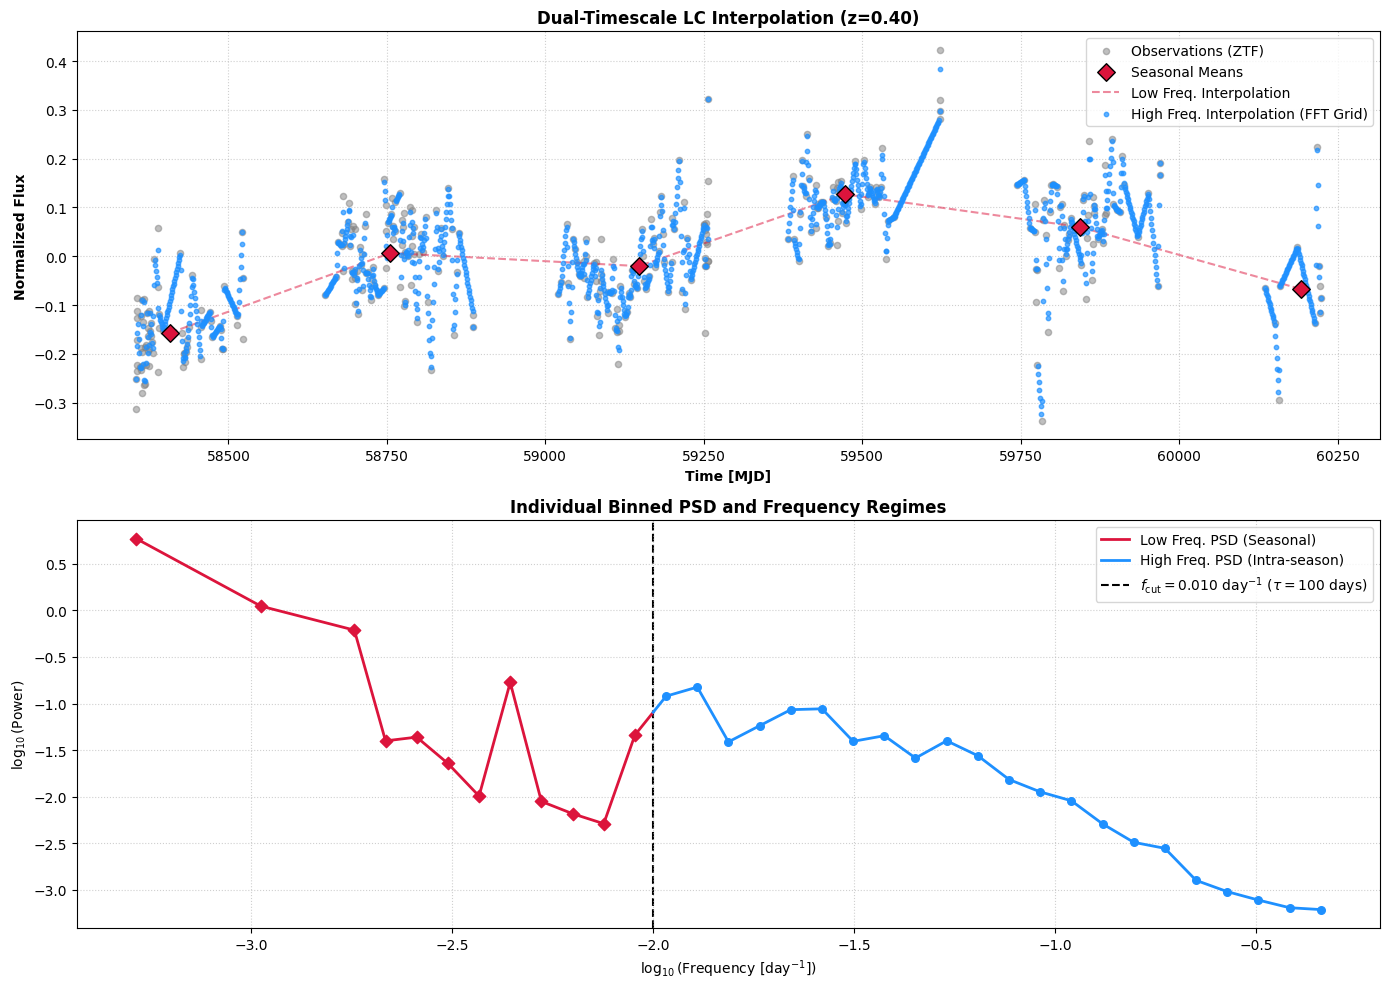

In [8]:
# ============================================================================
# EXTRA CELL: Single Object Visualization (Light Curve Interpolation + PSD)
# ============================================================================

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d

# --- 1. Select an example object ---
# Taking the first valid object and its corresponding binned PSD
obj_idx = 0 
ex_data = valid_data[obj_idx]
psd_example = binned_matrix_fft[obj_idx]

# Time and Flux arrays
t_raw, f_norm = ex_data['t_raw'], ex_data['flux_norm']
t_seas, f_seas = ex_data['t_season_means'], ex_data['flux_season_means']

# --- 2. Calculate the Cut-off Frequency (f_cut) ---
f_cut = 1.0 / SEASON_GAP_DAYS
tau_cut = SEASON_GAP_DAYS

# --- 3. Setup Figure ---
fig, (ax_lc, ax_psd) = plt.subplots(2, 1, figsize=(14, 10))

# ============================================================================
# TOP PANEL: Light Curve & Interpolations
# ============================================================================
# Raw data and seasonal means
ax_lc.scatter(t_raw, f_norm, color='gray', s=20, alpha=0.5, label='Observations (ZTF)')
ax_lc.scatter(t_seas, f_seas, color='crimson', s=80, marker='D', edgecolor='black', zorder=5, label='Seasonal Means')

# Low Frequency Interpolation
if len(t_seas) > 1:
    t_grid_low = np.linspace(t_seas.min(), t_seas.max(), 200)
    intp_low = interp1d(t_seas, f_seas, kind='linear', bounds_error=False, fill_value='extrapolate')(t_grid_low)
    ax_lc.plot(t_grid_low, intp_low, color='crimson', lw=1.5, ls='--', alpha=0.5, label='Low Freq. Interpolation')

# High Frequency Interpolation
for s_idx, (t_s, f_s) in enumerate(zip(ex_data['seasons_t'], ex_data['seasons_f_norm'])):
    t_grid_high = np.linspace(t_s.min(), t_s.max(), int((t_s.max()-t_s.min())/MIN_CADENCE_DAYS) + 1)
    if len(t_grid_high) > 1:
        intp_high = interp1d(t_s, f_s, kind='linear')(t_grid_high)
        lbl = 'High Freq. Interpolation (FFT Grid)' if s_idx == 0 else ""
        ax_lc.scatter(t_grid_high, intp_high, color='dodgerblue', s=10, alpha=0.7, zorder=3, label=lbl)

ax_lc.set_xlabel('Time [MJD]', fontweight='bold')
ax_lc.set_ylabel('Normalized Flux', fontweight='bold')
ax_lc.set_title(f'Dual-Timescale LC Interpolation (z={ex_data["Z"]:.2f})', fontweight='bold', fontsize=12)
ax_lc.legend(loc='upper right')
ax_lc.grid(ls=':', alpha=0.6)

# ============================================================================
# BOTTOM PANEL: Power Spectral Density with exact f_cut connection
# ============================================================================
# Filter out NaNs for a clean line plot
valid_psd_mask = ~np.isnan(psd_example) & (psd_example > 0)
x_f = bin_centers[valid_psd_mask]
y_p = psd_example[valid_psd_mask]

# Convert to log10 space for plotting and linear interpolation
x_f_log = np.log10(x_f)
y_p_log = np.log10(y_p)
log_f_cut = np.log10(f_cut)

# Find the indices bordering f_cut to interpolate the exact meeting point
idx_after = np.searchsorted(x_f_log, log_f_cut)
idx_before = idx_after - 1

# Interpolate the exact power value at the f_cut line
if 0 <= idx_before < len(x_f_log) and 0 <= idx_after < len(x_f_log):
    x0, y0 = x_f_log[idx_before], y_p_log[idx_before]
    x1, y1 = x_f_log[idx_after], y_p_log[idx_after]
    
    # Linear interpolation in log-log space
    y_cut_log = y0 + (y1 - y0) * (log_f_cut - x0) / (x1 - x0)
    
    # Create plotting arrays that meet exactly at the f_cut boundary
    x_low_plot = np.append(x_f_log[:idx_after], log_f_cut)
    y_low_plot = np.append(y_p_log[:idx_after], y_cut_log)
    
    x_high_plot = np.insert(x_f_log[idx_after:], 0, log_f_cut)
    y_high_plot = np.insert(y_p_log[idx_after:], 0, y_cut_log)
else:
    # Fallback if f_cut is somehow outside the data range
    mask_low = x_f_log < log_f_cut
    x_low_plot, y_low_plot = x_f_log[mask_low], y_p_log[mask_low]
    x_high_plot, y_high_plot = x_f_log[~mask_low], y_p_log[~mask_low]

# Plot Low Frequency Regime (from Seasonal Means)
# Using zorder to ensure lines and markers layer correctly
ax_psd.plot(x_low_plot, y_low_plot, color='crimson', lw=2, zorder=2, label='Low Freq. PSD (Seasonal)')
# Add markers only on the actual data points (excluding the interpolated boundary point)
ax_psd.scatter(x_f_log[:idx_after], y_p_log[:idx_after], color='crimson', marker='D', s=40, zorder=3)

# Plot High Frequency Regime (from Intra-season)
ax_psd.plot(x_high_plot, y_high_plot, color='dodgerblue', lw=2, zorder=2, label='High Freq. PSD (Intra-season)')
# Add markers only on the actual data points
ax_psd.scatter(x_f_log[idx_after:], y_p_log[idx_after:], color='dodgerblue', marker='o', s=30, zorder=3)

# Draw the f_cut boundary
f_cut_label = r"$f_{\rm cut} = " + f"{f_cut:.3f}" + r" \ \mathrm{day}^{-1} \ (\tau = " + f"{int(tau_cut)}" + r" \ \mathrm{days})$"
ax_psd.axvline(log_f_cut, color='black', ls='--', lw=1.5, zorder=1, label=f_cut_label)

ax_psd.set_xlabel(r"$\log_{10}(\mathrm{Frequency} \ [\mathrm{day}^{-1}])$", fontweight='bold')
ax_psd.set_ylabel(r"$\log_{10}(\mathrm{Power})$", fontweight='bold')
ax_psd.set_title(f'Individual Binned PSD and Frequency Regimes', fontweight='bold', fontsize=12)
ax_psd.legend(loc='upper right')
ax_psd.grid(ls=':', alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(plots_dir_base, "Single_Object_LC_and_PSD_Regimes.png"), dpi=200)
plt.show()